# Global Sensitivity Analysis of a DCF: Tornado Charts versus Sobol Indices and Shapley Effects for Correlated Inputs, with Ranges from Damodaran's Industry Data and a Gaussian-Process Surrogate

Every valuation memo has a **tornado chart**: each assumption is moved to a low and a high value, one at a time, and the bars show how much the value changes. It is simple and it can mislead. It ignores **interactions** (higher growth matters more when margins are high), it depends on arbitrary low and high values, and it treats inputs as independent when, in reality, the cost of capital and the terminal growth rate both move with interest rates.

**Global sensitivity analysis** asks a better question: if the uncertainty in each input were removed, how much of the **variance** of the value would disappear?

- **Sobol indices** (first-order *S₁* and total *S_T*) split the variance of the output among inputs and their interactions, for independent inputs.
- **Shapley effects** (Owen, 2014; Song, Nelson and Staum, 2016) share the variance fairly among inputs even when they are **correlated**, using the cooperative-game value from economics.
- A **Gaussian-process surrogate**, fitted to a few hundred runs of the model, can stand in for an expensive model (a full three-statement or LBO model in a spreadsheet) and reproduce the indices from far fewer evaluations.

The model is a standard free-cash-flow-to-the-firm DCF of a company with USD 1 billion of revenue. Its eight inputs are given realistic ranges from the **cross-section of U.S. non-financial industries in Aswath Damodaran's data** (operating margins, sales-to-capital ratios, costs of capital, expected growth), and the risk-free rate from FRED caps the terminal growth rate.

**Data.** Damodaran Online (U.S. industry operating margins, cost of capital, sales to invested capital and fundamental growth, January 2026 update); FRED (10-year Treasury yield).

**Methods.** FCFF DCF with margin convergence and reinvestment from sales-to-capital, one-at-a-time sensitivity (tornado), scenario analysis, Sobol first-order and total indices (Saltelli sampling, Jansen estimators, bootstrap intervals), Shapley effects with a Gaussian copula, Gaussian-process regression surrogate.

**Key output.** Which assumptions really drive a DCF value, whether the tornado chart ranks them differently, how much of the variance comes from interactions, how correlation between the discount rate and terminal growth changes the picture, and how many model runs a surrogate needs.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import io
import itertools
from scipy import stats
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
DAMODARAN = "https://pages.stern.nyu.edu/~adamodar/pc/datasets/"
REVENUE0 = 1000.0  # USD million
YEARS = 10  # explicit forecast years
N_SOBOL = 2**14  # base sample for Saltelli's scheme
N_BOOT = 200
# correlation between the cost of capital and terminal growth (both move with
# rates)
RHO_WACC_G = 0.6
RHO_GROWTH_MARGIN = 0.3

print(f"run on {dt.date.today():%Y-%m-%d}")

run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Input ranges from the industry cross-section

Each input's range is the 10th to 90th percentile of the corresponding statistic across Damodaran's U.S. industries (financial industries excluded, where operating margins and capital are not comparable). Inputs are drawn uniformly within those ranges, except where noted.

In [3]:
def damodaran(name):
    x = pd.read_excel(
        io.BytesIO(requests.get(DAMODARAN + name, timeout=120).content),
        sheet_name="Industry Averages",
        header=None,
    )
    i = x.index[x.iloc[:, 0].astype(str).str.strip().eq("Industry Name")][0]
    x.columns = x.iloc[i].astype(str).str.strip()
    return x.iloc[i + 1 :].set_index("Industry Name")


def fetch():
    m = damodaran("margin.xls")[["Pre-tax Unadjusted Operating Margin"]]
    w = damodaran("wacc.xls")[["Cost of Capital", "Tax Rate"]]
    c = damodaran("capex.xls")[["Sales/ Invested Capital (LTM)"]]
    g = damodaran("fundgrEB.xls")[["Expected Growth in EBIT"]]
    return (
        m.join(w)
        .join(c)
        .join(g)
        .apply(pd.to_numeric, errors="coerce")
        .reset_index()
    )


D = cached("damodaran_dcf_inputs", fetch, max_age_hours=24 * 90).set_index(
    "Industry Name"
)
D.index = D.index.str.strip()
D = D[
    ~D.index.str.contains(
        r"(?i)bank|insurance|financial|brokerage|investment|reit|total"
        r" market|real estate"
    )
]
RF = fred.get_series("DGS10").dropna().iloc[-1] / 100
q = lambda c, lo=0.10, hi=0.90: (
    float(D[c].quantile(lo)),
    float(D[c].quantile(hi)),
)
RANGES = {
    "revenue growth (yrs 1–5)": q("Expected Growth in EBIT"),
    "target operating margin": q("Pre-tax Unadjusted Operating Margin"),
    "initial operating margin (share of target)": (0.6, 1.0),
    "years to reach target margin": (3.0, 10.0),
    "sales to invested capital": q("Sales/ Invested Capital (LTM)"),
    "cost of capital": q("Cost of Capital"),
    "terminal growth": (0.01, min(RF, 0.04)),
    "tax rate": q("Tax Rate"),
}
NAMES = list(RANGES)
LO, HI = np.array([r[0] for r in RANGES.values()]), np.array(
    [r[1] for r in RANGES.values()]
)
BASE = (LO + HI) / 2
print(f"{len(D)} non-financial industries; 10-year Treasury {RF:.2%}")
pd.DataFrame(
    {"low (10th pct)": LO, "base (midpoint)": BASE, "high (90th pct)": HI},
    index=NAMES,
).round(3)

81 non-financial industries; 10-year Treasury 4.88%


,low (10th pct),base (midpoint),high (90th pct)
revenue growth (yrs 1–5),-0.01,0.08,0.17
target operating margin,0.03,0.15,0.26
initial operating margin (share of target),0.60,0.80,1.00
years to reach target margin,3.00,6.50,10.00
sales to invested capital,0.57,2.04,3.51
cost of capital,0.05,0.07,0.09
terminal growth,0.01,0.03,0.04
tax rate,0.03,0.09,0.15


## 3. The DCF

Revenue grows at the input rate for five years and fades linearly to terminal growth by year 10. The operating margin starts at a share of the target and converges linearly to it. Reinvestment = change in revenue / sales-to-capital. Free cash flow to the firm = EBIT × (1 − tax) − reinvestment, discounted at the cost of capital, plus a terminal value in which reinvestment is set so that return on capital in perpetuity equals the cost of capital (no value from growth after year 10, Damodaran's convention). The function is vectorised: one call values thousands of input sets.

In [4]:
def dcf(X):
    X = np.atleast_2d(X)
    g1, m_t, m0s, yrs, s2c, wacc, gt, tax = X.T
    t = np.arange(1, YEARS + 1)[None, :]
    g = np.where(
        t <= 5,
        g1[:, None],
        g1[:, None] + (gt[:, None] - g1[:, None]) * (t - 5) / (YEARS - 5),
    )
    rev = REVENUE0 * np.cumprod(1 + g, axis=1)
    rev_prev = np.c_[np.full(len(X), REVENUE0), rev[:, :-1]]
    m0 = m_t * m0s
    margin = m0[:, None] + (m_t - m0)[:, None] * np.minimum(
        t / yrs[:, None], 1
    )
    ebit_at = rev * margin * (1 - tax[:, None])
    reinv = (rev - rev_prev) / s2c[:, None]
    fcff = ebit_at - reinv
    disc = (1 + wacc[:, None]) ** t
    pv = (fcff / disc).sum(1)
    ebit_term = rev[:, -1] * (1 + gt) * m_t * (1 - tax)
    tv = ebit_term * (1 - gt / wacc) / (wacc - gt)
    return pv + tv / disc[:, -1]


V0 = dcf(BASE)[0]
print(
    f"Base-case value: USD {V0:,.0f} m for USD {REVENUE0:,.0f} m of revenue"
    f" (EV/sales {V0 / REVENUE0:.2f})"
)

Base-case value: USD 2,832 m for USD 1,000 m of revenue (EV/sales 2.83)


## 4. Tornado chart and scenarios

One at a time, each input moves to its low and high value while the others stay at the base; the bars are ranked by their width. Three scenarios move all inputs together (pessimistic = every input at the end that lowers value).

In [5]:
rows = []
for i, n in enumerate(NAMES):
    lo, hi = BASE.copy(), BASE.copy()
    lo[i], hi[i] = LO[i], HI[i]
    v_lo, v_hi = dcf(lo)[0], dcf(hi)[0]
    rows.append({
        "input": n,
        "value at low": v_lo,
        "value at high": v_hi,
        "swing": abs(v_hi - v_lo),
    })
TORN = (
    pd.DataFrame(rows).set_index("input").sort_values("swing", ascending=False)
)
TORN["tornado rank"] = np.arange(1, len(TORN) + 1)
sign = np.sign(
    TORN.loc[NAMES, "value at high"] - TORN.loc[NAMES, "value at low"]
).to_numpy()
pess, opt = np.where(sign > 0, LO, HI), np.where(sign > 0, HI, LO)
print(
    f"Scenarios: pessimistic USD {dcf(pess)[0]:,.0f} m · base {V0:,.0f} m ·"
    f" optimistic {dcf(opt)[0]:,.0f} m"
)
TORN.round(1)

Scenarios: pessimistic USD 323 m · base 2,832 m · optimistic 13,776 m


,value at low,value at high,swing,tornado rank
input,,,,
target operating margin,398.90,"5,264.10","4,865.20",1
revenue growth (yrs 1–5),"1,867.90","4,376.10","2,508.30",2
cost of capital,"3,932.10","2,172.30","1,759.80",3
sales to invested capital,"2,062.90","2,957.40",894.50,4
tax rate,"3,048.10","2,614.90",433.20,5
terminal growth,"2,735.60","2,932.00",196.50,6
initial operating margin (share of target),"2,755.60","2,907.40",151.80,7
years to reach target margin,"2,880.30","2,783.60",96.70,8


## 5. Sobol indices

With independent uniform inputs, Saltelli's scheme draws two matrices *A* and *B* (16,384 rows each) and, for each input *i*, a matrix *A_B⁽ⁱ⁾* equal to *A* with column *i* taken from *B*: 16,384 × 10 = 163,840 model runs. Jansen's estimators give the first-order index *S₁* (the share of variance explained by the input alone) and the total index *S_T* (including all its interactions); *S_T − S₁* measures how much an input matters through interactions. Bootstrap gives 95% intervals.

In [6]:
def sobol(f, n, d, g):
    A, B = g.random((n, d)), g.random((n, d))
    fA, fB = f(A), f(B)
    fAB = np.empty((d, n))
    for i in range(d):
        ABi = A.copy()
        ABi[:, i] = B[:, i]
        fAB[i] = f(ABi)

    def est(idx):
        a, b, ab = fA[idx], fB[idx], fAB[:, idx]
        var = np.var(np.r_[a, b])
        # Saltelli (2010)
        s1 = np.array([np.mean(b * (ab[i] - a)) for i in range(d)]) / var
        # Jansen (1999)
        st = (
            np.array([0.5 * np.mean((a - ab[i]) ** 2) for i in range(d)]) / var
        )
        return s1, st

    s1, st = est(np.arange(n))
    boot = [est(g.integers(0, n, n)) for _ in range(N_BOOT)]
    b1, bt = np.array([b[0] for b in boot]), np.array([b[1] for b in boot])
    return (
        s1,
        st,
        np.percentile(b1, [2.5, 97.5], 0),
        np.percentile(bt, [2.5, 97.5], 0),
        np.var(np.r_[fA, fB]),
        2 * n + d * n,
    )


to_x = lambda U: LO + U * (HI - LO)
t0 = time.time()
S1, ST, CI1, CIT, VAR, RUNS = sobol(
    lambda U: dcf(to_x(U)), N_SOBOL, len(NAMES), rng
)
SOB = pd.DataFrame(
    {
        "S1": S1,
        "S1 low": CI1[0],
        "S1 high": CI1[1],
        "ST": ST,
        "ST low": CIT[0],
        "ST high": CIT[1],
    },
    index=NAMES,
)
SOB["interactions (ST − S1)"] = SOB.ST - SOB.S1
SOB["Sobol rank"] = SOB.ST.rank(ascending=False).astype(int)
SOB = SOB.join(TORN["tornado rank"]).sort_values("ST", ascending=False)
print(
    f"{RUNS:,} model runs in {time.time() - t0:.1f} s · value: mean USD"
    f" {dcf(to_x(rng.random((20000, len(NAMES))))).mean():,.0f} m, standard"
    f" deviation USD {np.sqrt(VAR):,.0f} m · sum of first-order indices"
    f" {S1.sum():.2f} (1 − sum = share of variance from interactions)"
)
SOB.round(3)

163,840 model runs in 0.3 s · value: mean USD 2,886 m, standard deviation USD 1,841 m · sum of first-order indices 0.91 (1 − sum = share of variance from interactions)


,S1,S1 low,S1 high,ST,ST low,ST high,interactions (ST − S1),Sobol rank,tornado rank
target operating margin,0.68,0.65,0.72,0.74,0.72,0.75,0.06,1,1
revenue growth (yrs 1–5),0.13,0.11,0.15,0.21,0.20,0.22,0.08,2,2
cost of capital,0.08,0.06,0.09,0.10,0.10,0.11,0.03,3,3
sales to invested capital,0.02,0.01,0.02,0.02,0.02,0.02,0.01,4,4
tax rate,0.00,-0.00,0.01,0.01,0.01,0.01,0.01,5,5
terminal growth,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,6,6
initial operating margin (share of target),-0.00,-0.00,0.00,0.00,0.00,0.00,0.00,7,7
years to reach target margin,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,8,8


## 6. Shapley effects with correlated inputs

Inputs are not independent in practice. With a Gaussian copula, the cost of capital and the terminal growth rate are given a correlation of 0.6 (both rise with interest rates) and revenue growth and the target margin a correlation of 0.3. Sobol indices are no longer well defined; **Shapley effects** are: each input receives its average marginal contribution to the explained variance over all orders in which inputs can be "revealed" (8! = 40,320 orders, computed exactly through the 256 subsets of inputs). The explained variance of each subset is estimated by nested Monte Carlo (300 outer × 300 inner draws) from the conditional normal distributions of the copula. The effects are non-negative and sum to one.

In [7]:
d = len(NAMES)
C = np.eye(d)
iw, ig = NAMES.index("cost of capital"), NAMES.index("terminal growth")
ir, im = NAMES.index("revenue growth (yrs 1–5)"), NAMES.index(
    "target operating margin"
)
C[iw, ig] = C[ig, iw] = RHO_WACC_G
C[ir, im] = C[im, ir] = RHO_GROWTH_MARGIN


def f_z(Z):
    return dcf(to_x(stats.norm.cdf(Z)))


def shapley(Cm, f, n_outer=300, n_inner=300, g=None):
    g = g or np.random.default_rng(SEED)
    Lc = np.linalg.cholesky(Cm)
    Zall = g.standard_normal((50_000, d)) @ Lc.T
    var_y = f(Zall).var()
    # c(S) = Var(E[Y | X_S]) for every subset S (the explained-variance value
    # function), from the Gaussian conditional distributions
    c = {(): 0.0, tuple(range(d)): var_y}
    for k in range(1, d):
        for S in itertools.combinations(range(d), k):
            S = list(S)
            free = [j for j in range(d) if j not in S]
            K = Cm[np.ix_(free, S)] @ np.linalg.inv(Cm[np.ix_(S, S)])
            Lf = np.linalg.cholesky(
                Cm[np.ix_(free, free)]
                - K @ Cm[np.ix_(free, S)].T
                + 1e-12 * np.eye(len(free))
            )
            outer = g.standard_normal((n_outer, d)) @ Lc.T
            Z = np.empty((n_outer, n_inner, d))
            Z[:, :, S] = outer[:, None, S]
            Z[:, :, free] = (outer[:, S] @ K.T)[
                :, None, :
            ] + g.standard_normal((n_outer, n_inner, len(free))) @ Lf.T
            c[tuple(S)] = (
                f(Z.reshape(-1, d)).reshape(n_outer, n_inner).mean(1).var()
            )
    sh = np.zeros(d)
    for i in range(d):
        others = [j for j in range(d) if j != i]
        for k in range(d):
            w = (
                math.factorial(k)
                * math.factorial(d - k - 1)
                / math.factorial(d)
            )
            for S in itertools.combinations(others, k):
                sh[i] += w * (c[tuple(sorted(S + (i,)))] - c[S])
    return sh / var_y, var_y


import math

t0 = time.time()
SH_IND, V_IND = shapley(np.eye(d), f_z)
SH_COR, V_COR = shapley(C, f_z)
SHAP = pd.DataFrame(
    {
        "Shapley (independent)": SH_IND,
        "Shapley (correlated)": SH_COR,
        "Sobol S1": SOB.reindex(NAMES).S1.to_numpy(),
        "Sobol ST": SOB.reindex(NAMES).ST.to_numpy(),
    },
    index=NAMES,
).sort_values("Shapley (correlated)", ascending=False)
print(
    "Shapley effects: 2 × 254 conditional-variance estimates in"
    f" {time.time() - t0:.0f} s · standard deviation of value: independent USD"
    f" {np.sqrt(V_IND):,.0f} m, correlated USD {np.sqrt(V_COR):,.0f} m"
)
SHAP.round(3)

Shapley effects: 2 × 254 conditional-variance estimates in 38 s · standard deviation of value: independent USD 1,828 m, correlated USD 1,990 m


,Shapley (independent),Shapley (correlated),Sobol S1,Sobol ST
target operating margin,0.69,0.64,0.68,0.74
revenue growth (yrs 1–5),0.19,0.27,0.13,0.21
cost of capital,0.10,0.06,0.08,0.10
sales to invested capital,0.02,0.02,0.02,0.02
terminal growth,0.01,0.02,0.00,0.00
tax rate,0.01,0.01,0.00,0.01
years to reach target margin,0.01,0.00,0.00,0.00
initial operating margin (share of target),-0.02,-0.01,-0.00,0.00


## 7. A Gaussian-process surrogate

A real valuation model in a spreadsheet takes seconds per run, not microseconds, so 160,000 runs are out of reach. A Gaussian process (RBF kernel with automatic relevance determination) is fitted to *n* runs of the DCF (Latin-hypercube designs of 50 to 800 points), and the Sobol indices are recomputed on the surrogate. The question is how small *n* can be before the ranking of inputs changes.

In [8]:
def lhs(n, d, g):
    u = (np.argsort(g.random((n, d)), axis=0) + g.random((n, d))) / n
    return u


rows = []
TEST = rng.random((5000, d))
y_test = dcf(to_x(TEST))
for n in [50, 100, 200, 400, 800]:
    U = lhs(n, d, rng)
    y = dcf(to_x(U))
    mu, sd = y.mean(), y.std()
    gp = GaussianProcessRegressor(
        ConstantKernel(1.0) * RBF(np.ones(d), (1e-2, 1e2))
        + WhiteKernel(1e-4, (1e-8, 1e-1)),
        normalize_y=False,
        n_restarts_optimizer=2,
        random_state=SEED,
    ).fit(U, (y - mu) / sd)
    pred = lambda Uq: gp.predict(Uq) * sd + mu
    r2 = (
        1
        - ((y_test - pred(TEST)) ** 2).sum()
        / ((y_test - y_test.mean()) ** 2).sum()
    )
    s1g, stg, *_ = sobol(pred, 4096, d, np.random.default_rng(SEED + n))
    rows.append({
        "model runs": n,
        "surrogate R² (test)": r2,
        "max |ST error|": np.abs(stg - SOB.reindex(NAMES).ST.to_numpy()).max(),
        "Spearman of ST ranking": (
            pd.Series(stg).corr(
                pd.Series(SOB.reindex(NAMES).ST.to_numpy()), method="spearman"
            )
        ),
        "top-3 inputs identical": (
            set(np.argsort(-stg)[:3])
            == set(np.argsort(-SOB.reindex(NAMES).ST.to_numpy())[:3])
        ),
    })
GPR = pd.DataFrame(rows).set_index("model runs")
GPR.round(3)

,surrogate R² (test),max |ST error|,Spearman of ST ranking,top-3 inputs identical
model runs,,,,
50,0.99,0.08,1.00,True
100,1.00,0.04,1.00,True
200,1.00,0.01,1.00,True
400,1.00,0.01,1.00,True
800,1.00,0.01,1.00,True


## 8. Charts

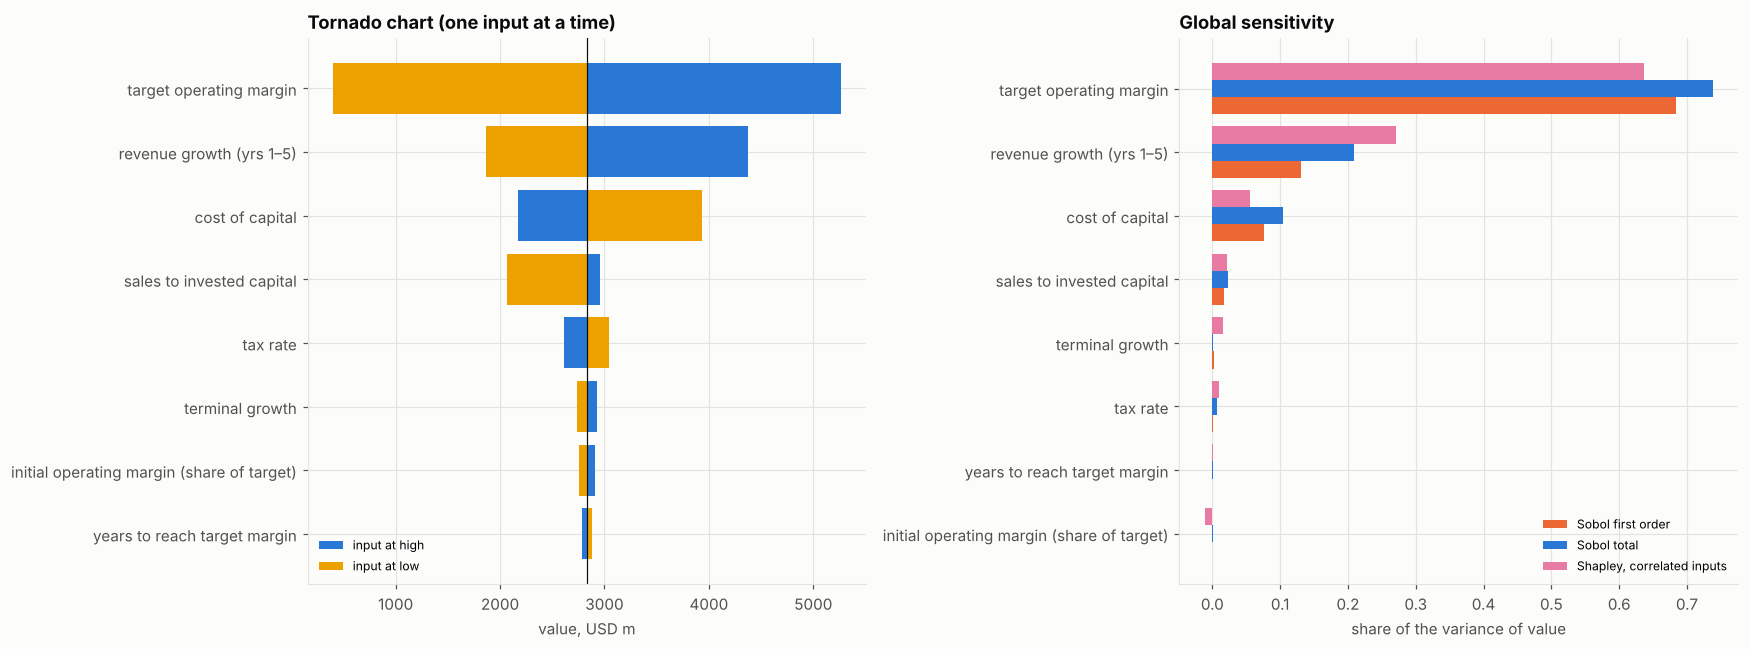

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
a = ax[0]
t = TORN.iloc[::-1]
a.barh(
    t.index,
    t["value at high"] - V0,
    left=V0,
    color=PALETTE[0],
    label="input at high",
)
a.barh(
    t.index,
    t["value at low"] - V0,
    left=V0,
    color=PALETTE[3],
    label="input at low",
)
a.axvline(V0, color=INK, lw=0.8)
a.set_xlabel("value, USD m")
a.set_title("Tornado chart (one input at a time)")
a.legend(fontsize=8)
a = ax[1]
s = SHAP.iloc[::-1]
y_ = np.arange(len(s))
a.barh(
    y_ - 0.27,
    s["Sobol S1"],
    height=0.27,
    color=PALETTE[1],
    label="Sobol first order",
)
a.barh(y_, s["Sobol ST"], height=0.27, color=PALETTE[0], label="Sobol total")
a.barh(
    y_ + 0.27,
    s["Shapley (correlated)"],
    height=0.27,
    color=PALETTE[4],
    label="Shapley, correlated inputs",
)
a.set_yticks(y_, s.index)
a.set_xlabel("share of the variance of value")
a.set_title("Global sensitivity")
a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_global_sensitivity")
plt.show()

In [10]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Distribution of value (independent vs correlated inputs)",
        "Surrogate accuracy by number of model runs",
    ),
)
Zi = rng.multivariate_normal(np.zeros(d), np.eye(d), 20000)
Zc = rng.multivariate_normal(np.zeros(d), C, 20000)
dash.add_trace(
    go.Histogram(
        x=f_z(Zi),
        name="independent",
        opacity=0.6,
        marker_color=PALETTE[0],
        nbinsx=80,
    ),
    1,
    1,
)
dash.add_trace(
    go.Histogram(
        x=f_z(Zc),
        name="correlated",
        opacity=0.6,
        marker_color=PALETTE[3],
        nbinsx=80,
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=GPR.index,
        y=GPR["surrogate R² (test)"],
        name="R²",
        line_color=PALETTE[1],
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=GPR.index,
        y=GPR["Spearman of ST ranking"],
        name="rank agreement",
        line_color=PALETTE[2],
    ),
    1,
    2,
)
dash.update_xaxes(type="log", title_text="model runs", row=1, col=2)
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    barmode="overlay",
    title="Global sensitivity analysis of a DCF",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

**One assumption dominates.** With ranges taken from the spread across U.S. industries, the DCF value of a company with USD 1 billion of revenue goes from USD 323 million in the pessimistic scenario to USD 13.8 billion in the optimistic one (base USD 2.8 billion). Its standard deviation across random input combinations is USD 1.8 billion. The **target operating margin** alone explains 68% of that variance (first-order Sobol index), and 74% including its interactions. Revenue growth comes next (13%; 21% with interactions), then the cost of capital (8%; 10%) and the sales-to-capital ratio (2%). The tax rate, terminal growth, the starting margin and the speed of margin convergence explain less than 1% each.

**Here the tornado chart gets the ranking right, and that is the point to check, not assume.** The one-at-a-time swings rank the inputs exactly as the total Sobol indices do. In this model interactions are modest: the first-order indices add up to 0.91, so 9% of the variance comes from combinations (high growth *and* high margins), mostly through growth (total minus first-order index 0.08) and margin (0.06). The tornado chart does not show that 9%, nor how far apart the bars really are: the margin's swing is twice the growth swing, but its share of variance is five times larger. In models with options, covenants or leverage thresholds, such as an LBO with a cash sweep or a project with a debt-service reserve, interactions are larger and the tornado ranking can be wrong.

**Correlation moves credit between inputs.** With the cost of capital and terminal growth correlated at 0.6 and growth and margin at 0.3, the value becomes more uncertain (standard deviation USD 2.0 billion instead of 1.8 billion). The Shapley effects reallocate the variance:

- revenue growth rises from 19% to 27%, because it now carries part of the margin's information;
- the margin falls from 70% to 64%;
- the cost of capital falls from 10% to 6%, because its effect is partly offset by the terminal growth that moves with it.

Sobol indices cannot be computed meaningfully with correlated inputs; Shapley effects can, and they are a fair split by construction. A small negative Shapley effect (−0.01 for the starting margin) is Monte Carlo noise around zero.

**A surrogate needs very few runs here.** A Gaussian process fitted to 50 runs of the model already predicts the value with an out-of-sample R² of 0.99 and ranks all eight inputs exactly as the 163,840-run Sobol analysis; with 200 runs the total indices are within 0.005. For a spreadsheet model that takes seconds per run, global sensitivity analysis is therefore cheap: a few hundred runs, then everything on the surrogate. Smooth models like a DCF are the easy case; models with kinks (cash sweeps, covenant breaches, option exercise) need more runs.

**Limitations.**
- **Ranges are the industry cross-section, not uncertainty about one company:** for a specific company the ranges would be narrower and centred on its own data, which can change the ranking.
- **Uniform marginal distributions and a Gaussian copula with assumed correlations:** different shapes give different indices.
- **Variance-based indices** describe what drives the spread of value, not what moves the median or the tails; moment-independent measures (Borgonovo's δ) would complement them.

In [11]:
TORN.to_csv(OUT_DIR / "tornado.csv")
SOB.to_csv(OUT_DIR / "sobol_indices.csv")
SHAP.to_csv(OUT_DIR / "shapley_effects.csv")
GPR.to_csv(OUT_DIR / "gp_surrogate.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_global_sensitivity.png, dashboard.html, dashboard.png, gp_surrogate.csv, shapley_effects.csv, sobol_indices.csv, tornado.csv


## References

- Damodaran, A. Damodaran Online: U.S. industry margins, cost of capital, capital expenditures and fundamental growth. https://pages.stern.nyu.edu/~adamodar/
- Federal Reserve Bank of St. Louis. FRED (10-year Treasury yield). https://fred.stlouisfed.org/
- Sobol', I. M. (2001). Global sensitivity indices for nonlinear mathematical models and their Monte Carlo estimates. *Mathematics and Computers in Simulation*, 55(1–3), 271–280.
- Saltelli, A., Annoni, P., Azzini, I., Campolongo, F., Ratto, M., & Tarantola, S. (2010). Variance based sensitivity analysis of model output. *Computer Physics Communications*, 181(2), 259–270.
- Jansen, M. J. W. (1999). Analysis of variance designs for model output. *Computer Physics Communications*, 117(1–2), 35–43.
- Owen, A. B. (2014). Sobol' indices and Shapley value. *SIAM/ASA Journal on Uncertainty Quantification*, 2(1), 245–251.
- Song, E., Nelson, B. L., & Staum, J. (2016). Shapley effects for global sensitivity analysis: Theory and computation. *SIAM/ASA Journal on Uncertainty Quantification*, 4(1), 1060–1083.
- Borgonovo, E., & Plischke, E. (2016). Sensitivity analysis: A review of recent advances. *European Journal of Operational Research*, 248(3), 869–887.
- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*. MIT Press.